In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas :", pd.__version__)
print("Matplotlib :", plt.matplotlib.__version__)
print("Seaborn :", sns.__version__)

Pandas : 2.3.1
Matplotlib : 3.10.3
Seaborn : 0.13.2


Importation du dataset nettoyé

In [2]:

df = pd.read_csv("data/clean/data_clean.csv")

# Afficher les 5 premières lignes
df.head()

,Store,Date,DayOfWeek,Sales,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,528,2013-06-08,6,3812,0,0,0,c,a,67578.758628,10,2011,1,29,2013,"Mar,Jun,Sept,Dec"
1,60,2013-09-24,2,6829,0,0,0,c,c,39604.358671,7,2008,0,0,0,Aucun
2,878,2014-07-01,2,6488,0,0,1,c,c,68892.844012,7,2011,0,0,0,Aucun
3,371,2013-03-29,5,4501,0,0,0,a,a,28895.722759,9,2013,0,0,0,Aucun
4,306,2013-05-26,7,10118,1,0,0,a,b,51879.787383,4,2002,0,0,0,Aucun


Afficher le nombre de lignes et de colonnes

In [4]:
df.shape

(803252, 16)

Afficher les informations générales du dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 803252 entries, 0 to 803251
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Store                      803252 non-null  int64  
 1   Date                       803252 non-null  object 
 2   DayOfWeek                  803252 non-null  int64  
 3   Sales                      803252 non-null  int64  
 4   Promo                      803252 non-null  int64  
 5   StateHoliday               803252 non-null  object 
 6   SchoolHoliday              803252 non-null  int64  
 7   StoreType                  803252 non-null  object 
 8   Assortment                 803252 non-null  object 
 9   CompetitionDistance        803252 non-null  float64
 10  CompetitionOpenSinceMonth  803252 non-null  int64  
 11  CompetitionOpenSinceYear   803252 non-null  int64  
 12  Promo2                     803252 non-null  int64  
 13  Promo2SinceWeek            80

In [6]:
df.describe()

,Store,DayOfWeek,Sales,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000,803252.000000
mean,558.006329,3.997109,6205.436570,0.380188,0.213137,37569.793330,5.549876,1713.653988,0.370439,9.236008,745.364802
std,321.889990,1.999964,3045.381611,0.485433,0.409524,21109.264613,3.904387,709.047131,0.482923,14.977577,971.694843
min,1.000000,1.000000,0.000000,0.000000,0.000000,27.601853,0.000000,0.000000,0.000000,0.000000,0.000000
25%,279.000000,2.000000,4524.000000,0.000000,0.000000,19726.622898,2.000000,2001.000000,0.000000,0.000000,0.000000
50%,558.000000,4.000000,6334.000000,0.000000,0.000000,37583.381105,6.000000,2006.000000,0.000000,0.000000,0.000000
75%,837.000000,6.000000,8144.000000,1.000000,0.000000,55220.873569,9.000000,2010.000000,1.000000,16.000000,2011.000000
max,1115.000000,7.000000,21387.000000,1.000000,1.000000,74973.315260,12.000000,2014.000000,1.000000,52.000000,2015.000000


 Afficher les catégories uniques des variables catégorielles

In [ ]:
print("Catégories de StateHoliday :")
print(df["StateHoliday"].unique())

print("\nCatégories de StoreType :")
print(df["StoreType"].unique())

print("\nCatégories de Assortment :")
print(df["Assortment"].unique())

print("\nCatégories de PromoInterval :")
print(df["PromoInterval"].unique())

Catégories de StateHoliday :
['0' 'b' 'a' 'c']

Catégories de StoreType :
['c' 'a' 'b' 'd']

Catégories de Assortment :
['a' 'c' 'b']

Catégories de PromoInterval :
['Mar,Jun,Sept,Dec' 'Aucun' 'Feb,May,Aug,Nov' 'Jan,Apr,Jul,Oct']



 Compter les occurrences de chaque catégorie

In [8]:

print("Répartition des types de magasins :")
print(df["StoreType"].value_counts())

print("\nRépartition des assortiments :")
print(df["Assortment"].value_counts())

print("\nRépartition des jours fériés :")
print(df["StateHoliday"].value_counts())

print("\nRépartition des intervalles promotionnels :")
print(df["PromoInterval"].value_counts())

Répartition des types de magasins :
StoreType
a    329234
b    202427
c    201706
d     69885
Name: count, dtype: int64

Répartition des assortiments :
Assortment
a    404901
c    327759
b     70592
Name: count, dtype: int64

Répartition des jours fériés :
StateHoliday
0    792028
a      6192
b      3931
c      1101
Name: count, dtype: int64

Répartition des intervalles promotionnels :
PromoInterval
Aucun               505696
Jan,Apr,Jul,Oct     103745
Feb,May,Aug,Nov      99432
Mar,Jun,Sept,Dec     94379
Name: count, dtype: int64


In [9]:
# Afficher toutes les catégories sans troncature
print(df["PromoInterval"].value_counts().to_string())

PromoInterval
Aucun               505696
Jan,Apr,Jul,Oct     103745
Feb,May,Aug,Nov      99432
Mar,Jun,Sept,Dec     94379


Visualiser la distribution du chiffre d'affaires

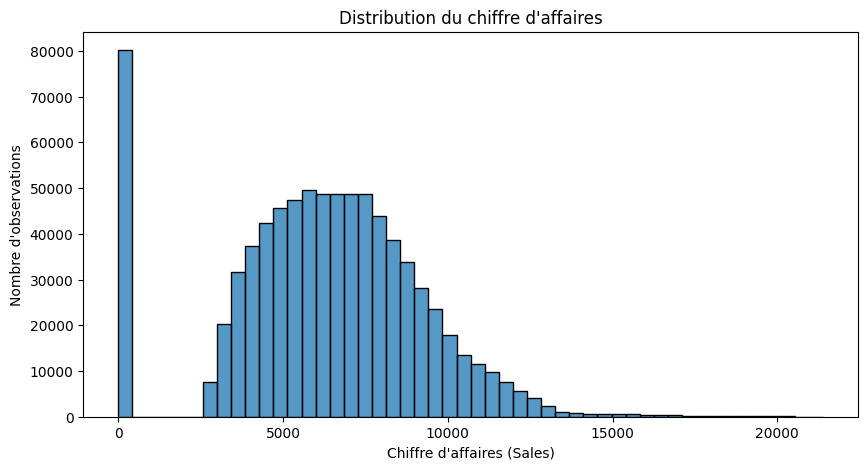

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Sales", bins=50)

plt.title("Distribution du chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (Sales)")
plt.ylabel("Nombre d'observations")

plt.show()

In [11]:
# Calculer quelques indicateurs sur la distribution des ventes

print("Vente minimale :", df["Sales"].min())
print("Vente maximale :", df["Sales"].max())
print("Vente moyenne :", round(df["Sales"].mean(), 2))
print("Vente médiane :", df["Sales"].median())
print("Nombre de ventes nulles :", (df["Sales"] == 0).sum())

Vente minimale : 0
Vente maximale : 21387
Vente moyenne : 6205.44
Vente médiane : 6334.0
Nombre de ventes nulles : 80190


Calculer le pourcentage de ventes nulles

In [12]:
pourcentage_ventes_nulles = (df["Sales"].eq(0).sum() / len(df)) * 100

print("Pourcentage de ventes nulles :", round(pourcentage_ventes_nulles, 2), "%")

Pourcentage de ventes nulles : 9.98 %


Calculer l'asymétrie de la distribution des ventes

In [14]:
asymetrie = df["Sales"].skew()

print("Coefficient d'asymétrie :", round(asymetrie, 3))

Coefficient d'asymétrie : -0.159


Interprétation de la distribution du chiffre d'affaires

L'analyse de la variable `Sales` montre que :

- Le chiffre d'affaires moyen est de 6 205,44.
- La médiane est de 6 334.
- Les ventes varient entre 0 et 21 387.
- Environ 9,98 % des observations présentent un chiffre d'affaires nul.
- Le coefficient d'asymétrie est de -0,159, ce qui indique une légère asymétrie vers la gauche.

Ces résultats montrent que les ventes présentent une certaine dispersion. Les observations avec un chiffre d'affaires nul méritent une attention particulière, car le dataset ne permet pas de déterminer directement si les magasins étaient fermés.



Visualiser la dispersion des ventes avec un boxplot

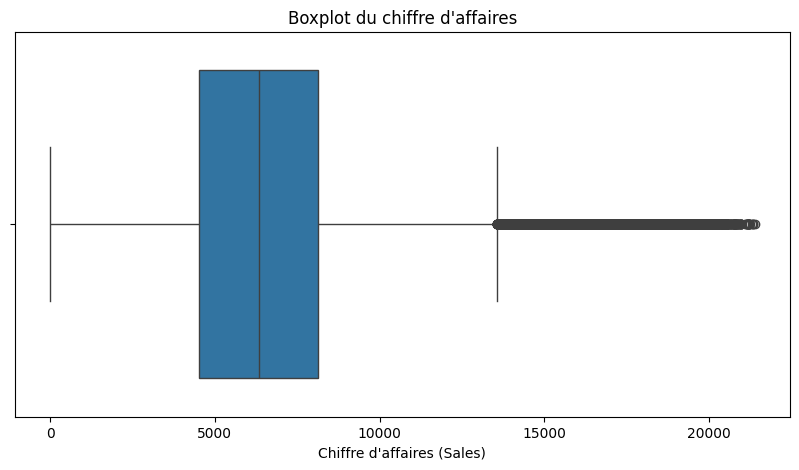

In [15]:

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Sales"])

plt.title("Boxplot du chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (Sales)")

plt.show()

In [16]:
# Calcul des quartiles
Q1 = df["Sales"].quantile(0.25)
Q2 = df["Sales"].quantile(0.50)
Q3 = df["Sales"].quantile(0.75)

# Calcul de l'écart interquartile
IQR = Q3 - Q1

# Calcul des limites des valeurs extrêmes
limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

# Affichage des résultats
print("Premier quartile (Q1) :", Q1)
print("Médiane (Q2) :", Q2)
print("Troisième quartile (Q3) :", Q3)
print("Écart interquartile (IQR) :", IQR)
print("Limite basse :", limite_basse)
print("Limite haute :", limite_haute)

# Nombre de valeurs extrêmes
outliers = df[
    (df["Sales"] < limite_basse) |
    (df["Sales"] > limite_haute)
]

print("Nombre de valeurs extrêmes :", len(outliers))

Premier quartile (Q1) : 4524.0
Médiane (Q2) : 6334.0
Troisième quartile (Q3) : 8144.0
Écart interquartile (IQR) : 3620.0
Limite basse : -906.0
Limite haute : 13574.0
Nombre de valeurs extrêmes : 5584


Première observation : 50 % des observations ont un chiffre d'affaires compris entre 4 524 et 8 144.

Deuxième observation : la limite basse est négative (-906), alors que notre chiffre d'affaires minimum est zéro. Il n'y a donc aucune valeur extrême inférieure selon cette règle.

Troisième observation : 5 584 observations dépassent la limite haute de 13 574. Elles représentent des ventes particulièrement élevées.

Calculer le pourcentage de valeurs extrêmes

In [17]:
pourcentage_outliers = (len(outliers) / len(df)) * 100

print("Pourcentage de valeurs extrêmes :", round(pourcentage_outliers, 2), "%")

Pourcentage de valeurs extrêmes : 0.7 %


Interprétation du boxplot de Sales

L'analyse du boxplot montre que :

- Le premier quartile (Q1) est de 4 524.
- La médiane est de 6 334.
- Le troisième quartile (Q3) est de 8 144.
- La moitié centrale des observations présente des ventes comprises entre 4 524 et 8 144.
- La limite supérieure de détection des valeurs extrêmes est de 13 574.
- 5 584 observations, soit environ 0,70 % du dataset, sont considérées comme des valeurs extrêmes.

Ces valeurs extrêmes correspondent à des journées où les ventes sont particulièrement élevées. Elles ne doivent pas être supprimées automatiquement, car elles peuvent représenter une activité commerciale réelle.

Nous les conserverons dans cette phase d'analyse et nous tiendrons compte de leur présence lors de la préparation des modèles prédictifs.

In [18]:
# Convertir la colonne Date au format datetime

df["Date"] = pd.to_datetime(df["Date"])

# Vérifier le type de la colonne
print(df["Date"].dtype)

datetime64[ns]


In [19]:
# Vérifier la période couverte par le dataset

print("Première date :", df["Date"].min())
print("Dernière date :", df["Date"].max())

Première date : 2013-01-01 00:00:00
Dernière date : 2014-12-23 00:00:00


In [20]:
# Regrouper les ventes de tous les magasins par date

ventes_journalieres = (
    df.groupby("Date")["Sales"]
    .sum()
    .reset_index()
)

# Afficher les 5 premières dates
print(ventes_journalieres.head())

        Date    Sales
0 2013-01-01  7461855
1 2013-01-02  7489714
2 2013-01-03  7435856
3 2013-01-04  7529890
4 2013-01-05  7505941


In [22]:
# Compter le nombre de dates disponibles

print("Nombre de dates :", len(ventes_journalieres))

Nombre de dates : 722


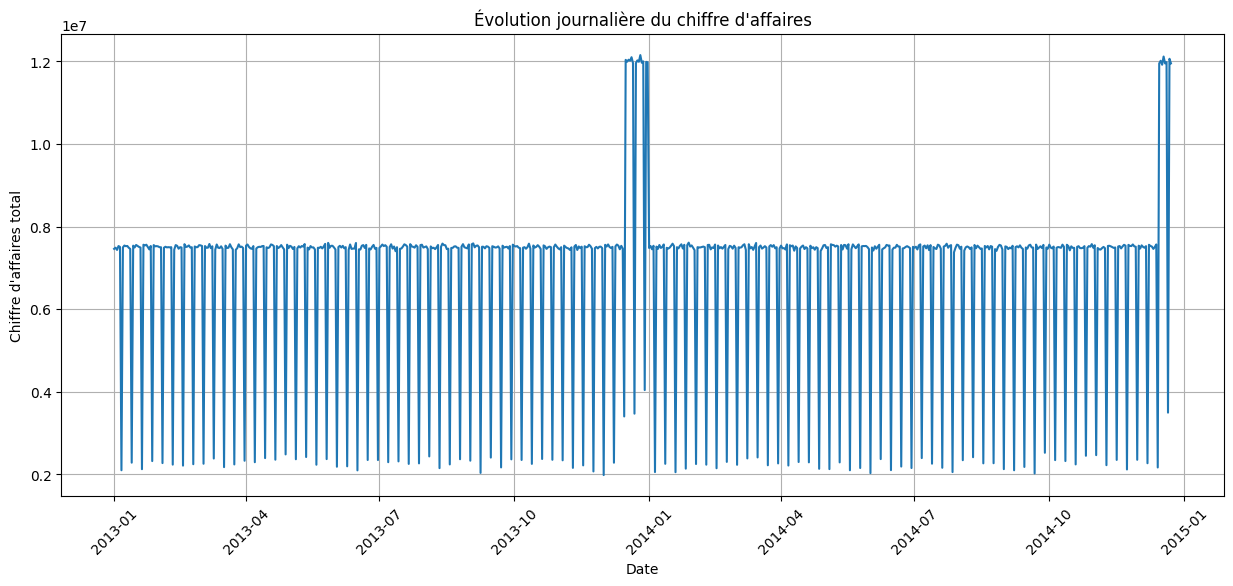

In [23]:
# Visualiser l'évolution journalière des ventes

plt.figure(figsize=(15, 6))

plt.plot(
    ventes_journalieres["Date"],
    ventes_journalieres["Sales"]
)

plt.title("Évolution journalière du chiffre d'affaires")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires total")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [24]:
# Regrouper les ventes par mois et par année

ventes_mensuelles = (
    df.groupby(df["Date"].dt.to_period("M"))["Sales"]
    .sum()
    .reset_index()
)

# Convertir les périodes en dates pour faciliter les graphiques
ventes_mensuelles["Date"] = ventes_mensuelles["Date"].dt.to_timestamp()

# Afficher les 10 premiers mois
print(ventes_mensuelles.head(10))

        Date      Sales
0 2013-01-01  211703383
1 2013-02-01  189174936
2 2013-03-01  206540539
3 2013-04-01  204847076
4 2013-05-01  212151650
5 2013-06-01  198639964
6 2013-07-01  212124231
7 2013-08-01  211901993
8 2013-09-01  199206684
9 2013-10-01  212068476


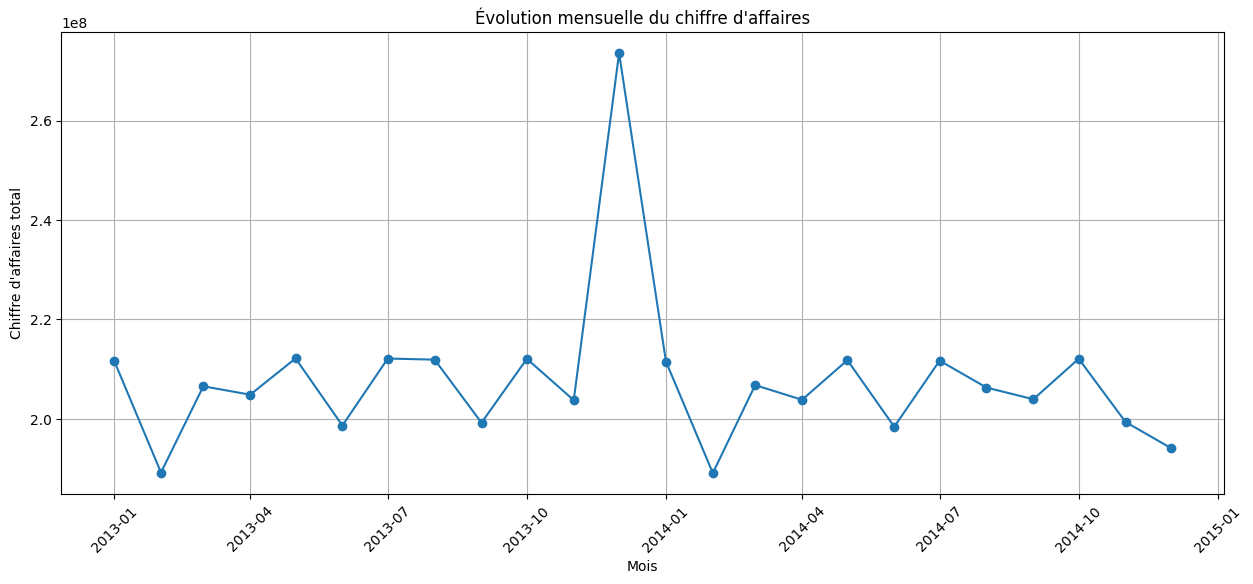

In [25]:
# Visualiser l'évolution mensuelle des ventes

plt.figure(figsize=(15, 6))

plt.plot(
    ventes_mensuelles["Date"],
    ventes_mensuelles["Sales"],
    marker="o"
)

plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires total")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [26]:
# Identifier le mois avec les ventes les plus élevées
meilleur_mois = ventes_mensuelles.loc[
    ventes_mensuelles["Sales"].idxmax()
]

# Identifier le mois avec les ventes les plus faibles
moins_bon_mois = ventes_mensuelles.loc[
    ventes_mensuelles["Sales"].idxmin()
]

print("Mois avec les ventes les plus élevées :")
print(meilleur_mois)

print("\nMois avec les ventes les plus faibles :")
print(moins_bon_mois)

Mois avec les ventes les plus élevées :
Date     2013-12-01 00:00:00
Sales              273610601
Name: 11, dtype: object

Mois avec les ventes les plus faibles :
Date     2014-02-01 00:00:00
Sales              189069524
Name: 13, dtype: object


In [27]:
# Ajouter le mois et l'année à chaque date
ventes_journalieres["Mois"] = (
    ventes_journalieres["Date"].dt.to_period("M")
)

# Calculer la moyenne des ventes journalières pour chaque mois
moyenne_ventes_mensuelles = (
    ventes_journalieres.groupby("Mois")["Sales"]
    .mean()
    .reset_index()
)

# Identifier le meilleur et le moins bon mois en moyenne journalière
print("Meilleure moyenne journalière :")
print(moyenne_ventes_mensuelles.loc[
    moyenne_ventes_mensuelles["Sales"].idxmax()
])

print("\nPlus faible moyenne journalière :")
print(moyenne_ventes_mensuelles.loc[
    moyenne_ventes_mensuelles["Sales"].idxmin()
])

Meilleure moyenne journalière :
Mois            2013-12
Sales    8826148.419355
Name: 11, dtype: object

Plus faible moyenne journalière :
Mois            2014-06
Sales    6613139.566667
Name: 17, dtype: object


 Comparaison des ventes mensuelles

L'analyse des ventes mensuelles montre que décembre 2013 possède le chiffre d'affaires total le plus élevé, avec 273 610 601, tandis que février 2014 possède le total le plus faible, avec 189 069 524.

Cependant, les mois n'ayant pas tous le même nombre de jours, nous avons également calculé la moyenne des ventes journalières pour chaque mois.

Les résultats montrent que :
- Décembre 2013 présente la moyenne journalière la plus élevée : 8 826 148,42.
- Juin 2014 présente la moyenne journalière la plus faible : 6 613 139,57.

Ces résultats suggèrent une activité commerciale plus importante en décembre. Cette hypothèse devra être approfondie avec l'analyse annuelle et les autres comparaisons.

In [28]:
# Regrouper les ventes par année

ventes_annuelles = (
    df.groupby(df["Date"].dt.year)["Sales"]
    .sum()
    .reset_index()
)

# Renommer les colonnes
ventes_annuelles.columns = ["Annee", "Sales"]

# Afficher les résultats
print(ventes_annuelles)

   Annee       Sales
0   2013  2535712229
1   2014  2448817107


In [29]:
# Garder uniquement les dates du 1er janvier au 23 décembre
df_periode_identique = df[
    df["Date"].dt.strftime("%m-%d") <= "12-23"
]

# Calculer les ventes par année sur cette même période
ventes_annuelles_comparables = (
    df_periode_identique
    .groupby(df_periode_identique["Date"].dt.year)["Sales"]
    .sum()
    .reset_index()
)

# Renommer les colonnes
ventes_annuelles_comparables.columns = ["Annee", "Sales"]

# Afficher les résultats
print(ventes_annuelles_comparables)

   Annee       Sales
0   2013  2447570557
1   2014  2448817107


Nous constatons que 2014 enregistre un chiffre d'affaires légèrement supérieur à 2013.

La différence est de 1 246 550.

C'est intéressant : notre première comparaison semblait montrer une baisse en 2014, mais après avoir harmonisé les périodes, nous observons une légère hausse.

Calculer le taux d'évolution entre 2013 et 2014

In [30]:
# Récupérer les ventes de chaque année
ventes_2013 = ventes_annuelles_comparables.loc[
    ventes_annuelles_comparables["Annee"] == 2013, "Sales"
].iloc[0]

ventes_2014 = ventes_annuelles_comparables.loc[
    ventes_annuelles_comparables["Annee"] == 2014, "Sales"
].iloc[0]

# Calculer le taux d'évolution
taux_evolution = ((ventes_2014 - ventes_2013) / ventes_2013) * 100

print("Taux d'évolution :", round(taux_evolution, 3), "%")

Taux d'évolution : 0.051 %


Interprétation de la comparaison annuelle

Pour comparer correctement les deux années, nous avons utilisé la même période : du 1er janvier au 23 décembre.

Les résultats montrent que :
- Le chiffre d'affaires de 2013 est de 2 447 570 557.
- Le chiffre d'affaires de 2014 est de 2 448 817 107.
- Le taux d'évolution entre 2013 et 2014 est de +0,051 %.

Le chiffre d'affaires a donc très légèrement augmenté en 2014. Cette variation étant très faible, nous pouvons considérer que le chiffre d'affaires est globalement stable entre les deux années sur la période étudiée.

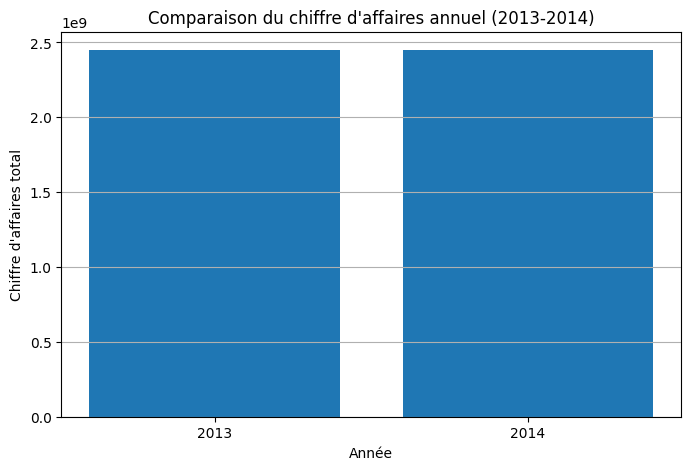

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    ventes_annuelles_comparables["Annee"].astype(str),
    ventes_annuelles_comparables["Sales"]
)

plt.title("Comparaison du chiffre d'affaires annuel (2013-2014)")
plt.xlabel("Année")
plt.ylabel("Chiffre d'affaires total")
plt.grid(axis="y")

plt.show()

Interprétation du graphique annuel

Le graphique compare le chiffre d'affaires total de 2013 et de 2014 sur une période identique, du 1er janvier au 23 décembre.

On observe que les deux années présentent des chiffres d'affaires très proches. Celui de 2014 est légèrement supérieur à celui de 2013, avec une progression de seulement 0,051 %.

Cela confirme que le chiffre d'affaires est globalement stable entre les deux années étudiées.

Calculer le chiffre d'affaires moyen par jour

In [32]:
ventes_par_jour = (
    df.groupby("DayOfWeek")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_par_jour)

   DayOfWeek        Sales
0          1  6946.109289
1          2  6942.061270
2          3  6867.568966
3          4  6870.515385
4          5  6862.404209
5          6  6866.587260
6          7  2074.919685


Interprétation du chiffre d'affaires selon les jours de la semaine

Les résultats montrent que le lundi présente le chiffre d'affaires moyen le plus élevé, avec 6 946,11, suivi de près par le mardi avec 6 942,06.

Du mercredi au samedi, les chiffres d'affaires moyens sont relativement proches.

Le dimanche se distingue par un chiffre d'affaires moyen beaucoup plus faible, de 2 074,92. Cela pourrait s'expliquer par la fermeture de nombreux magasins ce jour-là. Toutefois, le dataset ne contient pas de variable permettant de vérifier directement les jours d'ouverture.

Nous constatons donc que le jour de la semaine semble avoir une influence sur le chiffre d'affaires, particulièrement le dimanche.

Créer un graphique en barres

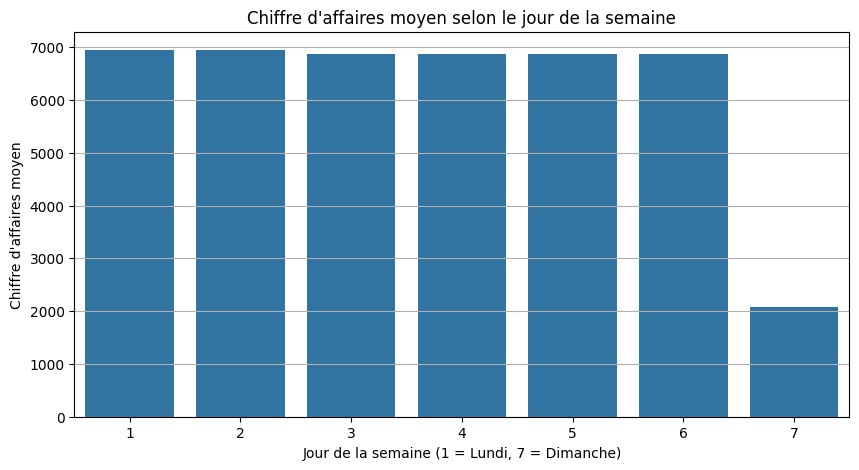

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ventes_par_jour,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon le jour de la semaine")
plt.xlabel("Jour de la semaine (1 = Lundi, 7 = Dimanche)")
plt.ylabel("Chiffre d'affaires moyen")
plt.grid(axis="y")

plt.show()

Calculer le chiffre d'affaires moyen

In [34]:
ventes_promo = (
    df.groupby("Promo")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_promo)

   Promo        Sales
0      0  5568.622400
1      1  7243.619227


Calculer l'écart en pourcentage

In [35]:
ventes_sans_promo = ventes_promo.loc[
    ventes_promo["Promo"] == 0, "Sales"
].iloc[0]

ventes_avec_promo = ventes_promo.loc[
    ventes_promo["Promo"] == 1, "Sales"
].iloc[0]

augmentation_promo = (
    (ventes_avec_promo - ventes_sans_promo)
    / ventes_sans_promo
) * 100

print("Augmentation avec promotion :", round(augmentation_promo, 2), "%")

Augmentation avec promotion : 30.08 %


Interprétation de l'influence des promotions

Les résultats montrent que :

- Sans promotion, le chiffre d'affaires moyen est de 5 568,62.
- Avec promotion, le chiffre d'affaires moyen est de 7 243,62.
- Le chiffre d'affaires moyen observé avec promotion est supérieur de 30,08 % à celui observé sans promotion.

Nous constatons donc une association positive entre la présence d'une promotion et le chiffre d'affaires.

Cependant, cette comparaison ne permet pas d'affirmer que les promotions sont l'unique cause de cette augmentation, car d'autres facteurs peuvent influencer les ventes.

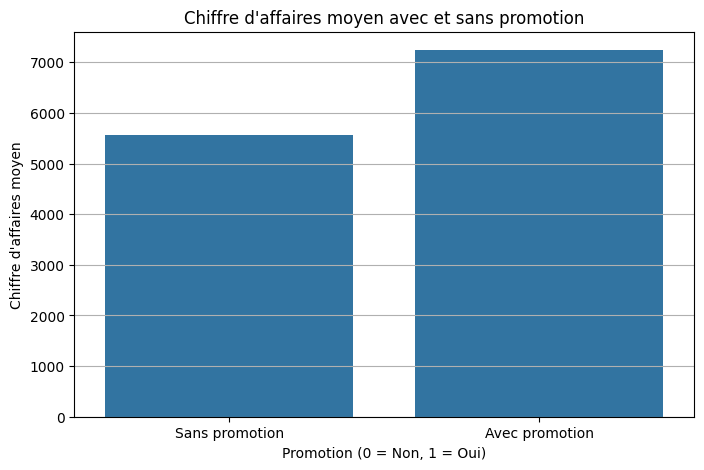

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ventes_promo,
    x="Promo",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen avec et sans promotion")
plt.xlabel("Promotion (0 = Non, 1 = Oui)")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks([0, 1], ["Sans promotion", "Avec promotion"])
plt.grid(axis="y")

plt.show()

étudier l'influence de Promo2
Calculer le chiffre d'affaires moyen

In [37]:
ventes_promo2 = (
    df.groupby("Promo2")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_promo2)

   Promo2        Sales
0       0  6172.208509
1       1  6261.907614


Nous constatons que :
- Les magasins sans Promo2 réalisent un chiffre d'affaires moyen de 6 172,21.
- Les magasins participant à Promo2 réalisent un chiffre d'affaires moyen de 6 261,91.
- La différence est relativement faible.

Calculer la différence en pourcentage

In [38]:
ventes_sans_promo2 = ventes_promo2.loc[
    ventes_promo2["Promo2"] == 0, "Sales"
].iloc[0]

ventes_avec_promo2 = ventes_promo2.loc[
    ventes_promo2["Promo2"] == 1, "Sales"
].iloc[0]

augmentation_promo2 = (
    (ventes_avec_promo2 - ventes_sans_promo2)
    / ventes_sans_promo2
) * 100

print(
    "Différence avec Promo2 :",
    round(augmentation_promo2, 2),
    "%"
)

Différence avec Promo2 : 1.45 %


Interprétation de l'influence de Promo2

Les résultats montrent que :

- Sans participation à Promo2, le chiffre d'affaires moyen est de 6 172,21.
- Avec participation à Promo2, le chiffre d'affaires moyen est de 6 261,91.
- Le chiffre d'affaires moyen des magasins participant à Promo2 est supérieur de 1,45 %.

La différence entre les deux groupes est donc faible.

Comparativement à la variable Promo, qui présente un écart de 30,08 %, Promo2 semble être moins fortement associée au chiffre d'affaires dans cette comparaison.

Il faut toutefois rappeler que Promo2 représente la participation à un programme de promotions récurrentes et ne signifie pas qu'une promotion est active chaque jour.

Créer le graphique comparatif

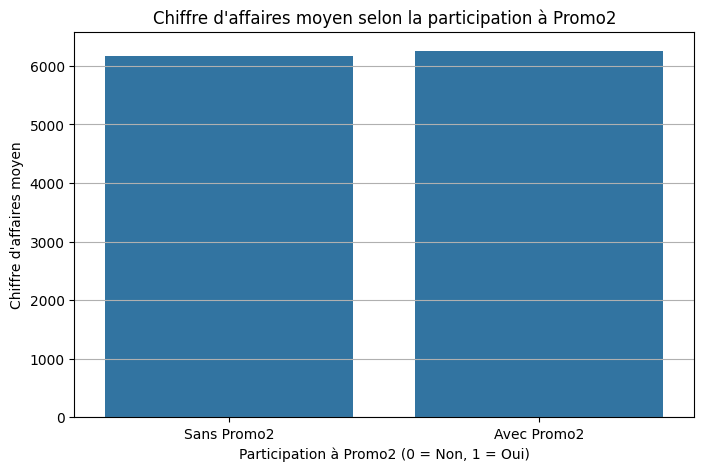

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ventes_promo2,
    x="Promo2",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon la participation à Promo2")
plt.xlabel("Participation à Promo2 (0 = Non, 1 = Oui)")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks([0, 1], ["Sans Promo2", "Avec Promo2"])
plt.grid(axis="y")

plt.show()

étudier l'influence des jours fériés
Calculer le chiffre d'affaires moyen

In [40]:
ventes_jours_feries = (
    df.groupby("StateHoliday")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_jours_feries)

  StateHoliday         Sales
0            0   6198.151727
1            a   6346.326066
2            b   6173.725515
3            c  10766.806540


1. Les jours normaux présentent un chiffre d'affaires moyen de 6 198,15.
2. Les jours fériés publics (a) présentent une moyenne légèrement supérieure : 6 346,33.
3. Pâques (b) présente une moyenne légèrement inférieure : 6 173,73.
4. Noël (c) présente le chiffre d'affaires moyen le plus élevé : 10 766,81.

Interprétation de l'influence des jours fériés

Les résultats montrent des différences de chiffre d'affaires moyen selon le type de journée.

- Les jours normaux présentent un chiffre d'affaires moyen de 6 198,15.
- Les jours fériés publics présentent une moyenne de 6 346,33.
- Les jours de Pâques présentent une moyenne de 6 173,73.
- Noël présente le chiffre d'affaires moyen le plus élevé, avec 10 766,81.

Nous observons donc que Noël se distingue par un chiffre d'affaires moyen nettement supérieur aux autres catégories.

Cependant, les groupes de jours fériés contiennent beaucoup moins d'observations que les jours normaux. Les résultats doivent donc être interprétés avec prudence.

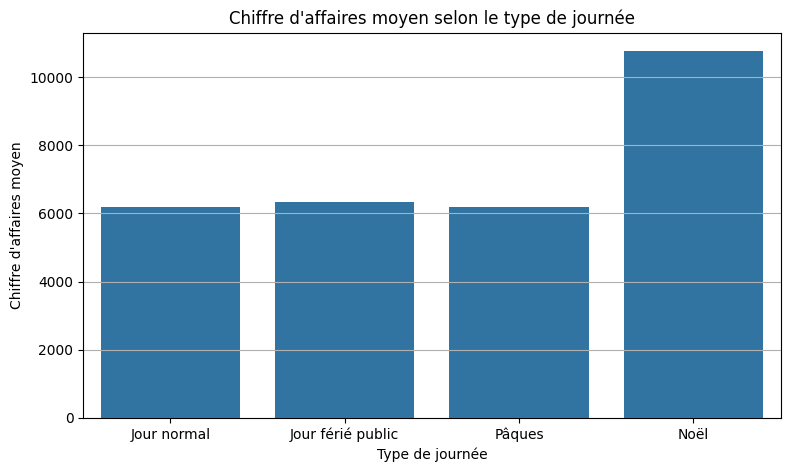

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ventes_jours_feries,
    x="StateHoliday",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon le type de journée")
plt.xlabel("Type de journée")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks(
    [0, 1, 2, 3],
    ["Jour normal", "Jour férié public", "Pâques", "Noël"]
)
plt.grid(axis="y")

plt.show()

calculer le chiffre d'affaires moyen

In [42]:
ventes_vacances = (
    df.groupby("SchoolHoliday")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_vacances)

   SchoolHoliday        Sales
0              0  6226.385499
1              1  6128.097101


Nous constatons que :
- Hors vacances scolaires, le chiffre d'affaires moyen est de 6 226,39.
- Pendant les vacances scolaires, il est de 6 128,10.
- Le chiffre d'affaires moyen est donc légèrement plus faible pendant les vacances scolaires.

Calculer la différence en pourcentage

In [43]:
ventes_hors_vacances = ventes_vacances.loc[
    ventes_vacances["SchoolHoliday"] == 0, "Sales"
].iloc[0]

ventes_pendant_vacances = ventes_vacances.loc[
    ventes_vacances["SchoolHoliday"] == 1, "Sales"
].iloc[0]

difference_vacances = (
    (ventes_pendant_vacances - ventes_hors_vacances)
    / ventes_hors_vacances
) * 100

print(
    "Différence pendant les vacances :",
    round(difference_vacances, 2),
    "%"
)

Différence pendant les vacances : -1.58 %


Interprétation de l'influence des vacances scolaires

Les résultats montrent que :

- Hors vacances scolaires, le chiffre d'affaires moyen est de 6 226,39.
- Pendant les vacances scolaires, il est de 6 128,10.
- Le chiffre d'affaires moyen pendant les vacances est inférieur de 1,58 % à celui observé hors vacances.

La différence est faible. Nous observons donc une légère baisse du chiffre d'affaires moyen pendant les vacances scolaires.

Cette comparaison montre une association, mais ne permet pas de conclure que les vacances scolaires sont directement responsables de cette baisse.

Créer le graphique comparatif

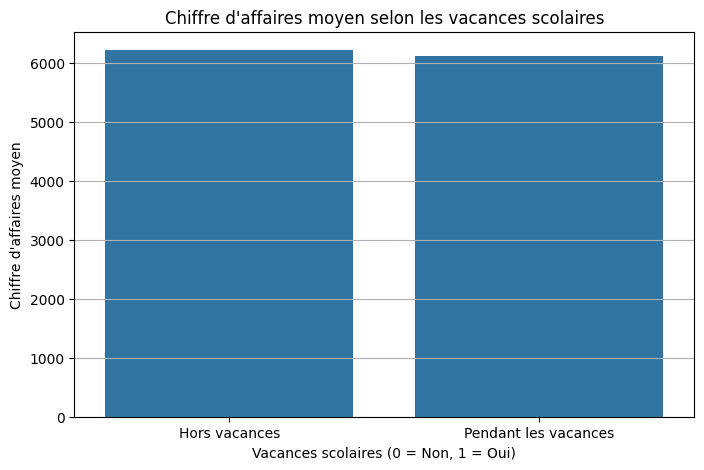

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ventes_vacances,
    x="SchoolHoliday",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon les vacances scolaires")
plt.xlabel("Vacances scolaires (0 = Non, 1 = Oui)")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks([0, 1], ["Hors vacances", "Pendant les vacances"])
plt.grid(axis="y")

plt.show()

calculer le chiffre d'affaires moyen par type de magasin

In [45]:
ventes_par_type = (
    df.groupby("StoreType")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_par_type)

  StoreType        Sales
0         a  6281.796573
1         b  6127.882990
2         c  6249.994289
3         d  5941.732918


### Interprétation du chiffre d'affaires selon le type de magasin

Les résultats montrent des différences de chiffre d'affaires moyen selon le type de magasin.

- Le type A présente le chiffre d'affaires moyen le plus élevé, avec 6 281,80.
- Le type C arrive en deuxième position, avec 6 249,99.
- Le type B présente une moyenne de 6 127,88.
- Le type D présente le chiffre d'affaires moyen le plus faible, avec 5 941,73.

Nous observons donc que le type de magasin semble être associé à des différences de chiffre d'affaires. Toutefois, les écarts entre les catégories restent relativement modérés.

calculer le chiffre d'affaires moyen par assortiment

In [46]:
ventes_par_assortiment = (
    df.groupby("Assortment")["Sales"]
    .mean()
    .reset_index()
)

print(ventes_par_assortiment)

  Assortment        Sales
0          a  6184.410500
1          b  6184.377507
2          c  6235.947031


Interprétation du chiffre d'affaires selon l'assortiment

Les résultats montrent que :

- La catégorie A (Basic) présente un chiffre d'affaires moyen de 6 184,41.
- La catégorie B (Extra) présente un chiffre d'affaires moyen de 6 184,38.
- La catégorie C (Extended) présente un chiffre d'affaires moyen de 6 235,95.

La catégorie C présente le chiffre d'affaires moyen le plus élevé. Cependant, les différences entre les trois catégories sont très faibles.

Nous pouvons donc constater que le niveau d'assortiment présente peu de différences dans le chiffre d'affaires moyen observé. Cette comparaison ne permet pas de conclure que l'assortiment influence directement les ventes.

Créer le graphique comparatif

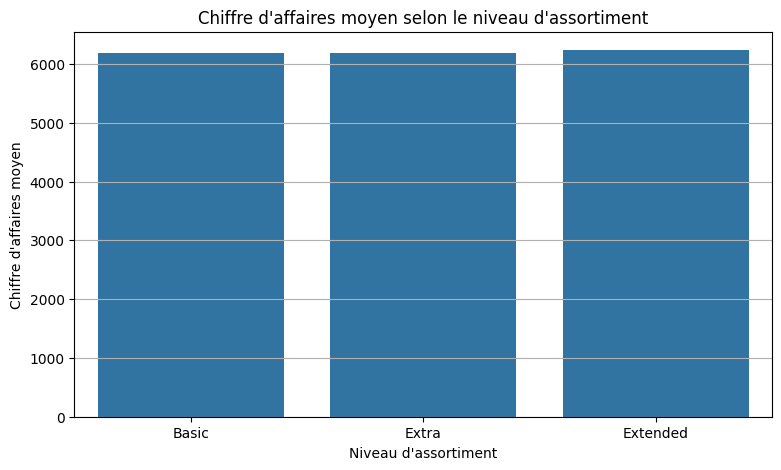

In [47]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ventes_par_assortiment,
    x="Assortment",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon le niveau d'assortiment")
plt.xlabel("Niveau d'assortiment")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks(
    [0, 1, 2],
    ["Basic", "Extra", "Extended"]
)
plt.grid(axis="y")

plt.show()

Afficher les statistiques descriptives

In [48]:
print(df["CompetitionDistance"].describe())

count    803252.000000
mean      37569.793330
std       21109.264613
min          27.601853
25%       19726.622898
50%       37583.381105
75%       55220.873569
max       74973.315260
Name: CompetitionDistance, dtype: float64


La distance moyenne est d'environ 37,57 km.



La moitié des observations présente une distance inférieure à environ 37,58 km.



Les distances sont assez dispersées : elles vont d'environ 28 mètres à 74,97 km.



La moyenne et la médiane sont très proches.

Créer un histogramme des distances

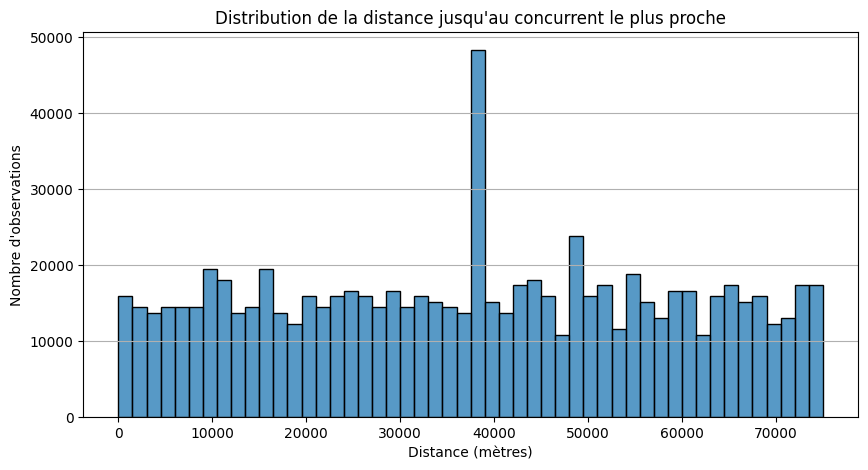

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="CompetitionDistance",
    bins=50
)

plt.title("Distribution de la distance jusqu'au concurrent le plus proche")
plt.xlabel("Distance (mètres)")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y")

plt.show()

comparer les ventes selon la distance concurrentielle

Nous voulons vérifier si les magasins ayant des concurrents proches réalisent un chiffre d'affaires moyen différent de ceux qui ont des concurrents éloignés.

Pour faciliter cette comparaison, nous allons diviser les distances en 4 groupes :
Groupe	Signification
Q1	Distances les plus faibles
Q2	Distances plutôt faibles
Q3	Distances plutôt élevées
Q4	Distances les plus élevées

Nous utilisons les quartiles pour répartir les observations en quatre groupes de tailles approximativement égales.

Créer les groupes de distance

In [50]:
df["GroupeDistance"] = pd.qcut(
    df["CompetitionDistance"],
    q=4,
    labels=["Q1 - Proche", "Q2 - Moyenne faible",
            "Q3 - Moyenne élevée", "Q4 - Éloignée"]
)

print(df["GroupeDistance"].value_counts())

GroupeDistance
Q2 - Moyenne faible    219718
Q1 - Proche            200993
Q4 - Éloignée          200286
Q3 - Moyenne élevée    182255
Name: count, dtype: int64


Comparer le chiffre d'affaires moyen

In [51]:
ventes_par_distance = (
    df.groupby("GroupeDistance", observed=True)["Sales"]
    .mean()
    .reset_index()
)

print(ventes_par_distance)

        GroupeDistance        Sales
0          Q1 - Proche  6169.458568
1  Q2 - Moyenne faible  6151.911828
2  Q3 - Moyenne élevée  6308.099904
3        Q4 - Éloignée  6206.838416


Interprétation de la relation entre la distance concurrentielle et les ventes

Les résultats montrent que :

- Le groupe Q1 (distances les plus faibles) présente un chiffre d'affaires moyen de 6 169,46.
- Le groupe Q2 présente une moyenne de 6 151,91.
- Le groupe Q3 présente la moyenne la plus élevée, avec 6 308,10.
- Le groupe Q4 (distances les plus élevées) présente une moyenne de 6 206,84.

Les différences entre les quatre groupes restent relativement faibles.

Nous ne constatons donc pas de relation régulière entre la distance du concurrent le plus proche et le chiffre d'affaires moyen. La distance concurrentielle semble, à elle seule, peu discriminante dans cette comparaison.

Créer le graphique comparatif

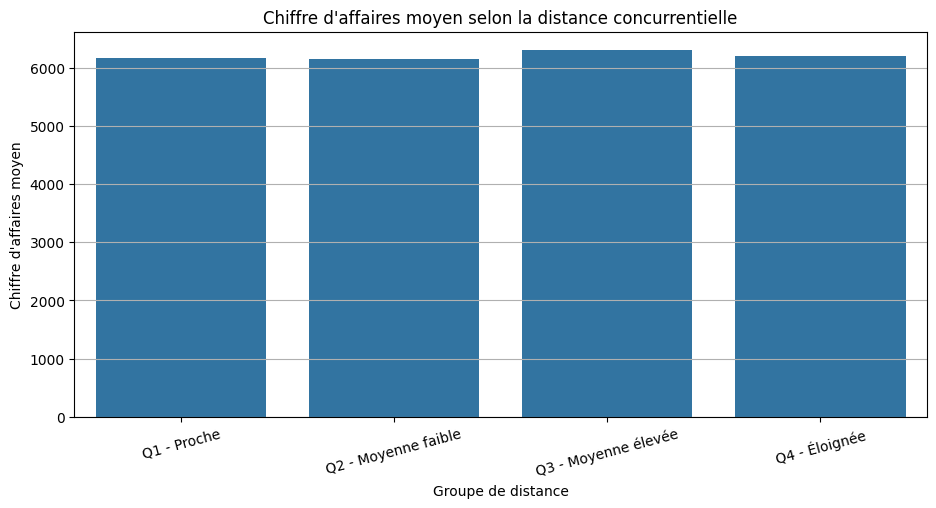

In [52]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=ventes_par_distance,
    x="GroupeDistance",
    y="Sales"
)

plt.title("Chiffre d'affaires moyen selon la distance concurrentielle")
plt.xlabel("Groupe de distance")
plt.ylabel("Chiffre d'affaires moyen")
plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()